<a href="https://colab.research.google.com/github/RohanDevre36/Black-Friday/blob/main/02_Causal_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import drive
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Connect this notebook to the project files in Google Drive.
drive.mount("/content/drive")

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Minimum_Wage_Causal_Analysis"
)

# Load the completed panel from disk.
# This notebook does not depend on variables in the first notebook.
panel_path = (
    PROJECT_DIR / "data_processed"
    / "qcew_state_private_food_services_panel_2010_2018.csv"
)

panel = pd.read_csv(
    panel_path,
    dtype={"area_fips": str, "industry_code": str}
)

# Confirm that the expected data loaded.
print("Panel records:", len(panel))
print("States/DC:", panel["area_fips"].nunique())
print("Years:", panel["year"].min(), "to", panel["year"].max())

Mounted at /content/drive
Panel records: 1836
States/DC: 51
Years: 2010 to 2018


In [3]:
##Create the treatment and time variables
# Keep New Jersey and the five provisional comparison states.
analysis_states = {
    "34000": "New Jersey",
    "42000": "Pennsylvania",
    "18000": "Indiana",
    "20000": "Kansas",
    "21000": "Kentucky",
    "51000": "Virginia"
}

analysis = panel.loc[
    panel["area_fips"].isin(analysis_states)
].copy()

# Add readable names and a quarterly time identifier.
analysis["state"] = analysis["area_fips"].map(analysis_states)

analysis["period"] = pd.PeriodIndex(
    analysis["year"].astype(str)
    + "Q"
    + analysis["qtr"].astype(str),
    freq="Q"
)

# treated = 1 for New Jersey, 0 for candidate comparison states.
analysis["treated"] = analysis["area_fips"].eq("34000").astype(int)

# post = 1 from January 2014 onward, for EVERY state.
analysis["post"] = analysis["year"].ge(2014).astype(int)

# did = 1 only for New Jersey after implementation.
# This interaction will identify the policy coefficient in a DiD model.
analysis["did"] = analysis["treated"] * analysis["post"]

# Flag quarters we will examine in sensitivity analyses.
# Do not remove them from the dataset yet.
analysis["anticipation_q4_2013"] = (
    analysis["period"].eq(pd.Period("2013Q4", freq="Q"))
).astype(int)

analysis["year_2018"] = analysis["year"].eq(2018).astype(int)

analysis = analysis.sort_values(
    ["state", "period"]
).reset_index(drop=True)

# Check the number of observations in each treatment/time group.
print("Observation counts by treatment and period:")
display(
    pd.crosstab(
        analysis["treated"],
        analysis["post"]
    ).rename(
        index={0: "Candidate controls", 1: "New Jersey"},
        columns={0: "Before 2014", 1: "2014 onward"}
    )
)

Observation counts by treatment and period:


post,Before 2014,2014 onward
treated,,
Candidate controls,80,100
New Jersey,16,20


In [4]:
##Prepare log outcomes
# Check outcomes before taking logs.
# Logs require positive, finite values.
outcome_columns = [
    "avg_monthly_employment",
    "avg_wkly_wage"
]

for column in outcome_columns:
    values = analysis[column]

    if (
        values.isna().any()
        or not np.isfinite(values).all()
        or values.le(0).any()
    ):
        raise ValueError(f"{column}: values need review before taking logs.")

# Create natural-log versions without replacing the original values.
analysis["log_employment"] = np.log(
    analysis["avg_monthly_employment"]
)
analysis["log_weekly_wage"] = np.log(
    analysis["avg_wkly_wage"]
)

# Verify one observation per state and quarter.
if analysis.duplicated(["area_fips", "period"]).any():
    raise ValueError("Duplicate state-quarter observations found.")

# Preview New Jersey's first five observations.
display(
    analysis.loc[
        analysis["treated"].eq(1),
        [
            "state", "period",
            "avg_monthly_employment", "log_employment",
            "avg_wkly_wage", "log_weekly_wage"
        ]
    ].head().round(4)
)

print("Log outcomes created successfully.")

,state,period,avg_monthly_employment,log_employment,avg_wkly_wage,log_weekly_wage
108,New Jersey,2010Q1,207820.0000,12.2444,313,5.7462
109,New Jersey,2010Q2,226856.3333,12.3321,324,5.7807
110,New Jersey,2010Q3,229676.3333,12.3444,338,5.8230
111,New Jersey,2010Q4,222316.6667,12.3119,345,5.8435
112,New Jersey,2011Q1,209776.3333,12.2538,318,5.7621


Log outcomes created successfully.


In [5]:
##Calculate a descriptive Difference-in-Differences estimate
# Calculate each state's average log outcomes before and after 2014.
state_period_means = (
    analysis.groupby(["state", "treated", "post"])[
        ["log_employment", "log_weekly_wage"]
    ]
    .mean()
    .reset_index()
)

results = []

for outcome in ["log_employment", "log_weekly_wage"]:
    # Put each state's pre-policy and post-policy averages side by side.
    state_changes = state_period_means.pivot(
        index="state",
        columns="post",
        values=outcome
    )

    # Calculate the post-minus-pre change for each state.
    state_changes["change"] = state_changes[1] - state_changes[0]

    nj_change = state_changes.loc["New Jersey", "change"]

    # Give each of the five candidate controls equal weight.
    control_change = state_changes.loc[
        state_changes.index != "New Jersey", "change"
    ].mean()

    # Subtract the controls' change from New Jersey's change.
    did_estimate = nj_change - control_change

    results.append({
        "outcome": outcome,
        "nj_log_change": nj_change,
        "controls_log_change": control_change,
        "did_log_difference": did_estimate,
        "relative_difference_pct": 100 * np.expm1(did_estimate)
    })

descriptive_did = pd.DataFrame(results)

display(descriptive_did.round(4))

,outcome,nj_log_change,controls_log_change,did_log_difference,relative_difference_pct
0,log_employment,0.1056,0.0906,0.0150,1.512
1,log_weekly_wage,0.1109,0.1161,-0.0051,-0.512


In [6]:
##Fit the baseline DiD regression

import statsmodels.formula.api as smf

# Convert quarterly periods to strings so the formula interface
# can treat each calendar quarter as a separate category.
analysis["time_id"] = analysis["period"].astype(str)

baseline_models = {}
regression_results = []

for outcome in ["log_employment", "log_weekly_wage"]:

    # C(state): accounts for persistent differences between states.
    # C(time_id): accounts for common shocks in each calendar quarter.
    # did: New Jersey's additional post-2014 change.
    #
    # Separate treated and post terms are unnecessary here:
    # state and time fixed effects already absorb them.
    model = smf.ols(
        formula=f"{outcome} ~ did + C(state) + C(time_id)",
        data=analysis,
        missing="raise"
    ).fit()

    # Retain the fitted model for later diagnostics.
    baseline_models[outcome] = model

    beta = model.params["did"]

    regression_results.append({
        "outcome": outcome,
        "did_log_coefficient": beta,
        "relative_difference_pct": 100 * np.expm1(beta),
        "observations": int(model.nobs)
    })

baseline_results = pd.DataFrame(regression_results)

# In this balanced panel, the baseline regression coefficient
# should match our descriptive DiD calculation.
descriptive_coefficients = (
    descriptive_did.set_index("outcome")["did_log_difference"]
)

for row in regression_results:
    if not np.isclose(
        row["did_log_coefficient"],
        descriptive_coefficients.loc[row["outcome"]],
        atol=1e-10
    ):
        raise ValueError("Regression and descriptive DiD do not match.")

display(baseline_results.round(4))

# Save the coefficient table without reporting unreliable default inference.
baseline_results.to_csv(
    PROJECT_DIR / "outputs" / "baseline_did_coefficients.csv",
    index=False
)

print("Verified: regression matches descriptive DiD.")

,outcome,did_log_coefficient,relative_difference_pct,observations
0,log_employment,0.0150,1.512,216
1,log_weekly_wage,-0.0051,-0.512,216


Verified: regression matches descriptive DiD.


In [8]:
##Check sensitivity to seasonality, anticipation, and the study endpoint

specifications = [
    ("Baseline", False, False, False),
    ("State-specific seasonality", True, False, False),
    ("Seasonality; exclude 2013Q4", True, True, False),
    ("Seasonality; end in 2017", True, False, True),
    ("Seasonality; both exclusions", True, True, True)
]

# Work on a copy so the original analysis table stays unchanged.
seasonal_data = analysis.copy()
seasonal_terms = []

# Calendar-quarter fixed effects already capture common seasonality.
# Add only DIFFERENCES in seasonal patterns relative to New Jersey.
reference_state = "New Jersey"

for state in sorted(seasonal_data["state"].unique()):
    if state == reference_state:
        continue

    # Use the geographic code to construct simple variable names.
    area_code = seasonal_data.loc[
        seasonal_data["state"].eq(state), "area_fips"
    ].iloc[0]

    # Q1 is the reference quarter; add indicators for Q2, Q3, and Q4.
    for quarter in [2, 3, 4]:
        term = f"season_{area_code}_q{quarter}"

        seasonal_data[term] = (
            seasonal_data["state"].eq(state)
            & seasonal_data["qtr"].eq(quarter)
        ).astype(int)

        seasonal_terms.append(term)

sensitivity_rows = []

for name, seasonal, exclude_anticipation, end_2017 in specifications:
    subset = seasonal_data.copy()

    # Exclude the anticipation quarter from every state.
    if exclude_anticipation:
        subset = subset.loc[
            subset["anticipation_q4_2013"].eq(0)
        ].copy()

    # Apply the shorter study window consistently across states.
    if end_2017:
        subset = subset.loc[subset["year"] <= 2017].copy()

    for outcome in ["log_employment", "log_weekly_wage"]:
        formula = f"{outcome} ~ did + C(state) + C(time_id)"

        if seasonal:
            formula += " + " + " + ".join(seasonal_terms)

        # Construct the model and check identification BEFORE fitting.
        model_spec = smf.ols(
            formula,
            data=subset,
            missing="raise"
        )

        design = model_spec.exog

        if np.linalg.matrix_rank(design) < design.shape[1]:
            raise ValueError(f"{name}: model matrix is not full rank.")

        model = model_spec.fit()
        beta = model.params["did"]

        sensitivity_rows.append({
            "specification": name,
            "outcome": outcome,
            "coefficient": beta,
            "relative_difference_pct": 100 * np.expm1(beta),
            "observations": int(model.nobs)
        })

sensitivity_results = pd.DataFrame(sensitivity_rows)

display(
    sensitivity_results.pivot(
        index="specification",
        columns="outcome",
        values="relative_difference_pct"
    ).round(3)
)

sensitivity_results.to_csv(
    PROJECT_DIR / "outputs" / "did_specification_sensitivity.csv",
    index=False
)

print("All model matrices passed the full-rank check.")

outcome,log_employment,log_weekly_wage
specification,,
Baseline,1.512,-0.512
Seasonality; both exclusions,1.021,-0.264
Seasonality; end in 2017,0.960,-0.289
Seasonality; exclude 2013Q4,1.575,-0.489
State-specific seasonality,1.512,-0.512


All model matrices passed the full-rank check.


In [9]:
##Check whether one control state drives the results

# Use the same sample restrictions for every leave-one-out model.
loo_sample = seasonal_data.loc[
    seasonal_data["anticipation_q4_2013"].eq(0)
    & seasonal_data["year"].le(2017)
].copy()

control_states = sorted(
    loo_sample.loc[
        loo_sample["treated"].eq(0), "state"
    ].unique()
)

loo_rows = []

# First fit all five controls, then omit each control one at a time.
for omitted_state in [None] + control_states:
    subset = loo_sample.copy()

    if omitted_state is not None:
        subset = subset.loc[
            subset["state"].ne(omitted_state)
        ].copy()

    # Remove seasonal indicators belonging to an omitted state.
    # Those columns would otherwise contain only zeros.
    active_terms = [
        term for term in seasonal_terms
        if subset[term].nunique() > 1
    ]

    for outcome in ["log_employment", "log_weekly_wage"]:
        formula = (
            f"{outcome} ~ did + C(state) + C(time_id)"
            + " + " + " + ".join(active_terms)
        )

        model_spec = smf.ols(
            formula,
            data=subset,
            missing="raise"
        )

        # Verify that every coefficient is identifiable.
        design = model_spec.exog
        if np.linalg.matrix_rank(design) < design.shape[1]:
            raise ValueError("Leave-one-out model is rank-deficient.")

        model = model_spec.fit()
        beta = model.params["did"]

        loo_rows.append({
            "omitted_control": omitted_state or "None: all five controls",
            "outcome": outcome,
            "relative_difference_pct": 100 * np.expm1(beta),
            "observations": int(model.nobs)
        })

loo_results = pd.DataFrame(loo_rows)

display(
    loo_results.pivot(
        index="omitted_control",
        columns="outcome",
        values="relative_difference_pct"
    ).round(3)
)

loo_results.to_csv(
    PROJECT_DIR / "outputs" / "did_leave_one_control_out.csv",
    index=False
)

outcome,log_employment,log_weekly_wage
omitted_control,,
Indiana,1.099,-0.385
Kansas,0.486,0.253
Kentucky,1.322,-0.188
None: all five controls,1.021,-0.264
Pennsylvania,0.618,-0.347
Virginia,1.586,-0.650


In [10]:
##Examine how the differences evolve over time

# Keep the same restrictions used for the leave-one-out analysis.
event_data = seasonal_data.loc[
    seasonal_data["anticipation_q4_2013"].eq(0)
    & seasonal_data["year"].le(2017)
].copy()

# Use 2012 as the reference year.
# This leaves 2013 visible as a possible anticipation/pre-policy diagnostic.
reference_year = 2012
event_terms = {}

for year in range(2010, 2018):
    if year == reference_year:
        continue

    term = f"nj_year_{year}"

    # Each indicator equals 1 only for New Jersey in that year.
    event_data[term] = (
        event_data["treated"].eq(1)
        & event_data["year"].eq(year)
    ).astype(int)

    event_terms[year] = term

event_rows = []

for outcome in ["log_employment", "log_weekly_wage"]:
    # Year-specific NJ indicators replace the single did term.
    # Keep state, calendar-quarter, and state-specific seasonal effects.
    formula = (
        f"{outcome} ~ C(state) + C(time_id)"
        + " + " + " + ".join(seasonal_terms)
        + " + " + " + ".join(event_terms.values())
    )

    model_spec = smf.ols(
        formula,
        data=event_data,
        missing="raise"
    )

    design = model_spec.exog
    if np.linalg.matrix_rank(design) < design.shape[1]:
        raise ValueError("Year-specific model is rank-deficient.")

    model = model_spec.fit()

    for year in range(2010, 2018):
        # The reference year's coefficient is zero by construction.
        beta = (
            0.0 if year == reference_year
            else model.params[event_terms[year]]
        )

        event_rows.append({
            "outcome": outcome,
            "year": year,
            "reference_year": reference_year,
            "log_difference": beta,
            "relative_difference_pct": 100 * np.expm1(beta)
        })

annual_event_results = pd.DataFrame(event_rows)

display(
    annual_event_results.pivot(
        index="year",
        columns="outcome",
        values="relative_difference_pct"
    ).round(3)
)

annual_event_results.to_csv(
    PROJECT_DIR / "outputs" / "annual_event_study_coefficients.csv",
    index=False
)

outcome,log_employment,log_weekly_wage
year,,
2010,0.855,0.549
2011,-0.021,0.286
2012,0.000,0.000
2013,0.649,0.777
2014,1.544,0.850
2015,0.297,0.241
2016,1.398,0.007
2017,2.267,-0.651


In [11]:
##Estimate uncertainty using the quarterly NJ–control gap

import statsmodels.formula.api as smf
from scipy.stats import t

gap_rows = []

# Use the same sample: through 2017, excluding Q4 2013.
gap_data = analysis.loc[
    analysis["year"].le(2017)
    & analysis["anticipation_q4_2013"].eq(0)
].copy()

for outcome in ["log_employment", "log_weekly_wage"]:
    # Arrange each state's log outcome in a separate column.
    wide = gap_data.pivot(
        index="period",
        columns="state",
        values=outcome
    ).sort_index()

    if wide.isna().any().any():
        raise ValueError("The quarterly gap has missing observations.")

    # Subtract the equal-weight control average from New Jersey.
    controls = wide.columns[wide.columns != "New Jersey"]
    gap = (
        wide["New Jersey"] - wide[controls].mean(axis=1)
    ).rename("gap").reset_index()

    # Recreate time variables within this quarterly series.
    gap["post"] = gap["period"].dt.year.ge(2014).astype(int)
    gap["quarter"] = gap["period"].dt.quarter

    # Check several lag choices instead of relying on just one.
    for lag in [1, 4, 8]:
        model = smf.ols(
            "gap ~ post + C(quarter)",
            data=gap,
            missing="raise"
        ).fit(
            cov_type="HAC",
            cov_kwds={"maxlags": lag, "use_correction": True},
            use_t=True
        )

        beta = model.params["post"]
        se = model.bse["post"]

        # Approximate 95% interval using residual degrees of freedom.
        critical = t.ppf(0.975, df=model.df_resid)
        lower = beta - critical * se
        upper = beta + critical * se

        gap_rows.append({
            "outcome": outcome,
            "HAC_lags": lag,
            "estimate_pct": 100 * np.expm1(beta),
            "lower_95_pct": 100 * np.expm1(lower),
            "upper_95_pct": 100 * np.expm1(upper),
            "quarters": int(model.nobs)
        })

gap_uncertainty = pd.DataFrame(gap_rows)

display(gap_uncertainty.round(3))

gap_uncertainty.to_csv(
    PROJECT_DIR / "outputs" / "did_gap_hac_intervals.csv",
    index=False
)

,outcome,HAC_lags,estimate_pct,lower_95_pct,upper_95_pct,quarters
0,log_employment,1,1.021,0.299,1.748,31
1,log_employment,4,1.021,0.149,1.901,31
2,log_employment,8,1.021,0.165,1.885,31
3,log_weekly_wage,1,-0.264,-0.724,0.199,31
4,log_weekly_wage,4,-0.264,-0.802,0.277,31
5,log_weekly_wage,8,-0.264,-0.830,0.305,31


In [12]:
##Run a pre-policy placebo check

# Use only pre-policy data and exclude the possible anticipation quarter.
placebo_data = analysis.loc[
    analysis["year"].lt(2014)
    & analysis["anticipation_q4_2013"].eq(0)
].copy()

placebo_rows = []

for outcome in ["log_employment", "log_weekly_wage"]:
    # Create a quarterly series of the NJ minus average-control gap.
    wide = placebo_data.pivot(
        index="period",
        columns="state",
        values=outcome
    ).sort_index()

    if wide.isna().any().any():
        raise ValueError("Missing observations in the placebo sample.")

    controls = wide.columns[wide.columns != "New Jersey"]

    gap = (
        wide["New Jersey"] - wide[controls].mean(axis=1)
    ).rename("gap").reset_index()

    # Assign a fake intervention date two years before the actual policy.
    gap["fake_post"] = gap["period"].dt.year.ge(2012).astype(int)
    gap["quarter"] = gap["period"].dt.quarter

    # Estimate the fake intervention difference, allowing seasonal gaps.
    # Report point estimates only: this placebo has just 15 quarters.
    model = smf.ols(
        "gap ~ fake_post + C(quarter)",
        data=gap,
        missing="raise"
    ).fit()

    beta = model.params["fake_post"]

    placebo_rows.append({
        "outcome": outcome,
        "fake_policy_start": "2012Q1",
        "placebo_difference_pct": 100 * np.expm1(beta),
        "quarters": int(model.nobs)
    })

placebo_results = pd.DataFrame(placebo_rows)

display(placebo_results.round(3))

placebo_results.to_csv(
    PROJECT_DIR / "outputs" / "pre_policy_placebo.csv",
    index=False
)

,outcome,fake_policy_start,placebo_difference_pct,quarters
0,log_employment,2012Q1,-0.169,15
1,log_weekly_wage,2012Q1,-0.137,15


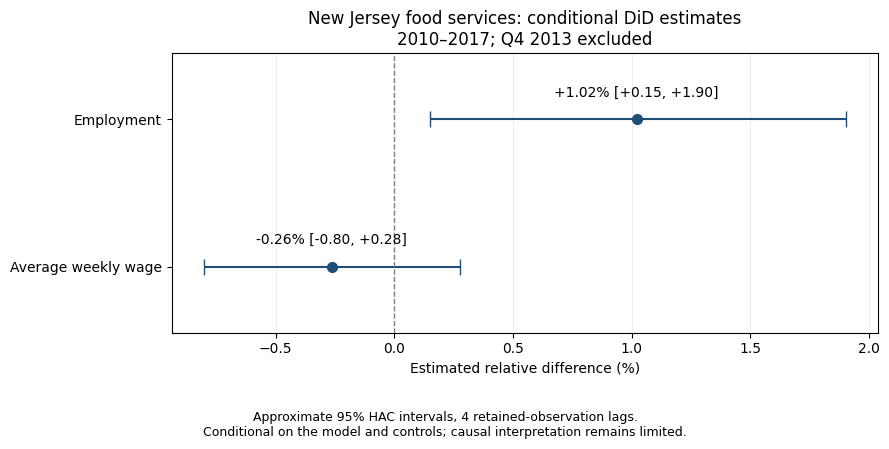

Saved: did_estimates_conditional_intervals.png


In [13]:
##Create the final estimate chart

# Select the four-lag results for the main uncertainty chart.
chart_results = (
    gap_uncertainty.loc[gap_uncertainty["HAC_lags"].eq(4)]
    .set_index("outcome")
    .loc[["log_employment", "log_weekly_wage"]]
    .copy()
)

labels = ["Employment", "Average weekly wage"]
positions = np.arange(len(labels))

# Calculate distances from each point estimate to its interval bounds.
errors = np.vstack([
    chart_results["estimate_pct"] - chart_results["lower_95_pct"],
    chart_results["upper_95_pct"] - chart_results["estimate_pct"]
])

fig, ax = plt.subplots(figsize=(9, 4.5))

# Draw point estimates with horizontal uncertainty intervals.
ax.errorbar(
    chart_results["estimate_pct"],
    positions,
    xerr=errors,
    fmt="o",
    color="#1f4e79",
    capsize=6,
    markersize=7
)

# Zero represents no relative difference under this specification.
ax.axvline(0, color="gray", linestyle="--", linewidth=1)

ax.set_yticks(positions)
ax.set_yticklabels(labels)
ax.invert_yaxis()
ax.set_xlabel("Estimated relative difference (%)")
ax.set_title(
    "New Jersey food services: conditional DiD estimates\n"
    "2010–2017; Q4 2013 excluded"
)
ax.grid(axis="x", alpha=0.2)

# Label estimates and intervals directly for easier reading.
for position, (_, row) in zip(positions, chart_results.iterrows()):
    ax.annotate(
        f"{row['estimate_pct']:+.2f}% "
        f"[{row['lower_95_pct']:+.2f}, {row['upper_95_pct']:+.2f}]",
        xy=(row["estimate_pct"], position),
        xytext=(0, 16),
        textcoords="offset points",
        ha="center",
        fontsize=10
    )

ax.margins(y=0.45)

# Explicitly state what the intervals cover and what remains uncertain.
fig.text(
    0.5, 0.02,
    "Approximate 95% HAC intervals, 4 retained-observation lags.\n"
    "Conditional on the model and controls; causal interpretation remains limited.",
    ha="center",
    fontsize=9
)

fig.tight_layout(rect=[0, 0.12, 1, 1])

chart_file = (
    PROJECT_DIR / "outputs" / "did_estimates_conditional_intervals.png"
)
fig.savefig(chart_file, dpi=200, bbox_inches="tight")
plt.show()

print(f"Saved: {chart_file.name}")

In [14]:
##Compare Pennsylvania alone with the five-state benchmark

# Keep the same time window and anticipation exclusion for both models.
benchmark_data = analysis.loc[
    analysis["year"].le(2017)
    & analysis["anticipation_q4_2013"].eq(0)
].copy()

control_groups = {
    "Pennsylvania only": ["Pennsylvania"],
    "Five-state average": [
        "Pennsylvania", "Indiana", "Kansas", "Kentucky", "Virginia"
    ]
}

benchmark_rows = []

for outcome in ["log_employment", "log_weekly_wage"]:
    # Put each state's quarterly outcome in a separate column.
    wide = benchmark_data.pivot(
        index="period",
        columns="state",
        values=outcome
    ).sort_index()

    for group_name, controls in control_groups.items():
        # Calculate NJ's gap relative to the selected control group.
        gap = (
            wide["New Jersey"] - wide[controls].mean(axis=1)
        ).rename("gap").reset_index()

        gap["post"] = gap["period"].dt.year.ge(2014).astype(int)
        gap["quarter"] = gap["period"].dt.quarter

        # Use the same seasonal adjustment and HAC settings in both models.
        model = smf.ols(
            "gap ~ post + C(quarter)",
            data=gap,
            missing="raise"
        ).fit(
            cov_type="HAC",
            cov_kwds={"maxlags": 4, "use_correction": True},
            use_t=True
        )

        beta = model.params["post"]
        lower, upper = model.conf_int(alpha=0.05).loc["post"]

        benchmark_rows.append({
            "comparison": group_name,
            "outcome": outcome,
            "estimate_pct": 100 * np.expm1(beta),
            "lower_95_pct": 100 * np.expm1(lower),
            "upper_95_pct": 100 * np.expm1(upper),
            "quarters": int(model.nobs)
        })

benchmark_results = pd.DataFrame(benchmark_rows)

display(benchmark_results.round(3))

# Save all results, regardless of their direction.
benchmark_results.to_csv(
    PROJECT_DIR / "outputs" / "did_control_group_comparison.csv",
    index=False
)

,comparison,outcome,estimate_pct,lower_95_pct,upper_95_pct,quarters
0,Pennsylvania only,log_employment,2.649,1.613,3.696,31
1,Five-state average,log_employment,1.021,0.149,1.901,31
2,Pennsylvania only,log_weekly_wage,0.068,-0.464,0.603,31
3,Five-state average,log_weekly_wage,-0.264,-0.802,0.277,31


##The findings summary

## Findings and Interpretation

### Study scope
This analysis examines private-sector food services and drinking places
in New Jersey. Outcomes are employment and average weekly wages.
It does not measure individual hourly earnings or cover all industries.

The intervention is the minimum wage policy beginning in January 2014,
including subsequent inflation-linked adjustments.

### Main conditional estimates
For 2010–2017, excluding Q4 2013 and using five equally weighted
comparison states:

| Outcome | Estimate | Approximate 95% HAC interval |
|---|---:|---:|
| Employment | +1.02% | +0.15% to +1.90% |
| Average weekly wage | −0.26% | −0.80% to +0.28% |

Intervals use four retained-observation HAC lags. They are conditional
on the model and comparison group, with only 31 quarterly observations.
The omitted quarter makes lag spacing an approximation.

### Robustness findings
- Using Pennsylvania alone increases the employment estimate to +2.65%.
- Leaving out individual controls produces employment estimates
  from +0.49% to +1.59%.
- The wage estimate changes sign when Kansas is excluded.
- A fake January 2012 intervention produces small point estimates:
  −0.17% for employment and −0.14% for weekly wages.
- Year-specific estimates fluctuate, and pre-policy differences remain.

### Interpretation
New Jersey's food services employment increased relative to the
selected controls under these specifications. However, the magnitude
depends on the comparison group, and the design does not establish
that the minimum wage policy caused the increase.

There is no clear evidence of a change in average weekly wages under
the reported conditional intervals. This does not establish that the
policy had no effect on hourly pay, hours worked, or worker earnings.

### Policy implications
These results alone do not justify recommending or rejecting a minimum
wage increase. Stronger conclusions require broader policy verification,
additional comparison groups, and checks for concurrent economic changes.

### Remaining limitations
- One treated state and a small, judgment-selected control group.
- Possible anticipation and cross-border spillovers.
- Incomplete review of other state and local policy changes.
- Average weekly wages reflect hours and employee composition.
- Industry classification changes across years require verification.
- No claim of a representative national policy effect.

##Source findings to your analysis notebook

## Additional Source Checks

### Concurrent local policies
Newark's legislative record documents adoption of a paid sick leave
ordinance on January 28, 2014.

This creates a potential confounder near the minimum wage intervention.
We have not established its implementation timing, affected employment
share, or effect on our outcomes.

Ending the analysis in 2017 avoids the statewide 2018 sick leave law
but does not eliminate earlier local policy overlap. Our state-level
models cannot separately identify these local policy effects.

Source:
https://newark.legistar.com/LegislationDetail.aspx?GUID=22C72D79-0A2C-4DF9-A597-9FF29C980CF6&ID=1518218&Options=&Search=

### Industry classification
Under the 2007 classification, restaurant groups included NAICS 7221
and 7222. Under the 2012 classification, these were grouped in 7225.

All fall within the broader food services and drinking places
subsector, NAICS 722, used in this project. This avoids that specific
lower-level code change, but does not establish complete continuity
of every establishment classification.

Source:
https://www.osha.gov/faq/2-3

### Implication for conclusions
The estimates remain conditional comparisons consistent with a DiD
framework. We cannot attribute the observed differences exclusively
to minimum wage policy.

The policy review is targeted, not an exhaustive audit of every
state and local policy in New Jersey and the comparison states.

In [17]:
from zipfile import ZipFile, ZIP_DEFLATED
from google.colab import files

# Save the analysis dataset used by our models.
# Convert quarterly periods to text for portable CSV storage.
analysis_export = analysis.copy()
analysis_export["period"] = analysis_export["period"].astype(str)

analysis_export.to_csv(
    PROJECT_DIR / "data_processed" / "six_state_analysis_panel.csv",
    index=False
)

# Collect notebooks, prepared datasets, and results.
# Exclude large raw archives because we already have download code.
folders_to_include = ["notebooks", "data_processed", "outputs"]
allowed_extensions = {".ipynb", ".csv", ".png", ".md", ".txt"}

# Verify that both notebooks were saved in the expected folder.
for notebook in [
    "01_Data_Collection.ipynb",
    "02_Causal_Analysis.ipynb"
]:
    if not (PROJECT_DIR / "notebooks" / notebook).exists():
        raise FileNotFoundError(
            f"Save {notebook} in the project's notebooks folder first."
        )

# Create a compact review package outside the folders being included.
package_path = PROJECT_DIR / "Minimum_Wage_Project_Review.zip"
included_count = 0

with ZipFile(package_path, "w", compression=ZIP_DEFLATED) as package:
    for folder in folders_to_include:
        for path in sorted((PROJECT_DIR / folder).rglob("*")):
            if path.is_file() and path.suffix.lower() in allowed_extensions:
                # Preserve project-relative folder names inside the ZIP.
                package.write(
                    path,
                    arcname=str(path.relative_to(PROJECT_DIR))
                )
                included_count += 1

    # Include environment details if available.
    for filename in ["requirements.txt", "environment.txt"]:
        path = PROJECT_DIR / filename
        if path.exists():
            package.write(path, arcname=filename)
            included_count += 1

print(f"Packaged {included_count} files.")
print(f"Size: {package_path.stat().st_size / (1024 ** 2):.2f} MB")

files.download(str(package_path))

Packaged 31 files.
Size: 0.55 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

##Analytical report

# Minimum Wage Policy, Employment, and Weekly Wages in New Jersey
## A Difference-in-Differences Analysis of Food Services, 2010–2018

## Executive Summary

This study investigates whether New Jersey’s minimum wage policy
beginning in January 2014 was associated with changes in employment
and average weekly wages in private-sector food services and drinking
places.

The analysis combines Bureau of Labor Statistics employment and wage
data with minimum wage histories published through FRED. A balanced
panel covers 50 states and Washington, DC, from 2010 through 2018.
The estimation sample uses New Jersey and five comparison states:
Pennsylvania, Indiana, Kansas, Kentucky, and Virginia.

In a specification covering 2010–2017 and excluding Q4 2013, New
Jersey’s employment increased approximately 1.02% relative to the
five-state benchmark. The approximate conditional 95% interval is
0.15% to 1.90%. The weekly wage difference is −0.26%, with an
interval of −0.80% to 0.28%.

These findings are sensitive to comparison-group choices. Using
Pennsylvania alone increases the employment estimate to 2.65%.
The weekly wage estimate changes sign when Kansas is excluded
from the pooled controls.

The study therefore identifies conditional differences rather than
establishing that minimum wage policy caused these outcomes.

## 1. Research Question and Scope

How did employment and average weekly wages in New Jersey’s
private-sector food services industry change after its January
2014 minimum wage increase, relative to comparison states?

The intervention includes the initial increase and subsequent
inflation-linked adjustments. It is not a constant $1 treatment
throughout the post-policy period.

The completed analysis focuses on NAICS 722, food services and
drinking places. Retail, unemployment, poverty, crime, and educational
attainment are outside the completed scope. The results should not
be generalized to all workers, industries, or US states.

## 2. Policy Background

New Jersey voters approved the minimum wage amendment on November
5, 2013. The general minimum wage increased from $7.25 to $8.25
per hour on January 1, 2014, an increase of approximately 13.79%.

The downloaded annual series records rates of $8.38 in 2015 and
2016, $8.44 in 2017, and $8.60 in 2018. The federal benchmark
remained $7.25 during the study window.

The approval date precedes implementation, creating a possible
anticipation period. Excluding Q4 2013 addresses one plausible
window but cannot rule out earlier responses.

Other policies complicate interpretation. Newark adopted a paid
sick leave ordinance on January 28, 2014. New Jersey’s statewide
earned sick leave law took effect on October 29, 2018. Excluding
2018 avoids the statewide implementation period but does not
remove earlier municipal policy overlap.

## 3. Data and Preparation

### Sources

Employment and wage outcomes come from the BLS Quarterly Census
of Employment and Wages (QCEW). Annual minimum wage histories
come from FRED series sourced from the US Department of Labor.

Historical QCEW data were retrieved from annual ZIP archives.
Annual minimum wage observations were used for policy screening,
rather than assumed to provide a complete quarterly legal timeline.

### Panel construction

Records were filtered to:
- The 50 states and Washington, DC.
- Private-sector ownership, code 5.
- Statewide three-digit industry records, aggregation code 55.
- Food services and drinking places, industry code 722.
- Four quarters per year from 2010 through 2018.

The resulting panel contains 1,836 observations:
51 geographic areas × 9 years × 4 quarters.

Coverage checks confirmed every expected state-year-quarter
combination, no duplicate keys, blank disclosure flags, and no
missing values in the selected outcome fields. No imputation
was required.

The six-state estimation panel contains 216 observations.
The restricted 2010–2017 sample excluding Q4 2013 contains 186
state-quarter observations, corresponding to 31 observed quarters.

### Outcome definitions

Quarterly average monthly employment was calculated as:

Employment = (Month 1 + Month 2 + Month 3 employment) / 3

This measures jobs, rather than unique workers.

Average weekly wages were retained as published by BLS. They
reflect hours, worker composition, and compensation; they are not
a direct measure of hourly wages or earnings for a fixed worker.

Both outcomes were transformed using natural logarithms.
Published wage values were analyzed in nominal dollars.

## 4. Exploratory Analysis and Control Selection

Pennsylvania was examined first because it is a neighboring
candidate with an unchanged annual wage series during the window.
Four additional states were screened: Indiana, Kansas, Kentucky,
and Virginia. Their downloaded annual series also remained $7.25.

This was a judgment-based candidate set, not an exhaustive or
optimized national control-selection procedure.

Pre-policy comparisons showed similar cumulative growth in some
cases, but differences within the period. In Q4 2013, employment
grew 3.90% year over year in New Jersey versus 1.58% in Pennsylvania.

Against the five-state benchmark, New Jersey’s cumulative
employment growth lagged by 0.88 percentage points in both 2011
and 2012, before approximately catching up in 2013.

These findings do not establish parallel trends. They motivate
reporting several comparisons and treating causal claims cautiously.

## 5. Statistical Methodology

### Difference-in-Differences

The baseline model is:

log(Y_st) = state effect + calendar-quarter effect
            + beta × (New Jersey_s × Post2014_t) + error_st

State effects account for persistent differences between states.
Calendar-quarter effects account for shocks shared across states
in each specific quarter.

Additional specifications allow recurring seasonal patterns to
differ across states.

The coefficient is converted to a relative percentage difference:

Percentage difference = 100 × [exp(beta) − 1]

This is a ratio-based interpretation of log outcomes, not a direct
estimate of arithmetic-average job counts or individual wage gains.

### Identification assumptions

A causal interpretation would require a credible parallel
untreated trend, sufficiently limited anticipation and spillovers,
and no unaccounted differential shocks driving the comparison.

The study does not establish that these assumptions hold.
Fixed effects do not remove time-varying state-specific confounding.

RDD was not used because this design does not provide a suitable
running variable and assignment cutoff. Synthetic control was not
implemented; the completed estimator is DiD.

### Uncertainty

Ordinary OLS standard errors were not used for substantive inference.
With one treated state and five controls, conventional state-clustered
inference is also fragile.

Instead, the analysis models the quarterly difference between New
Jersey’s log outcome and the equal-weight control average, with
seasonal indicators and HAC standard errors.

Intervals use a finite-sample covariance correction and a
t-distribution reference. Lag choices of 1, 4, and 8 were examined.

These are approximate conditional intervals. Only 31 observations
remain in the restricted series, and removing Q4 2013 means HAC
lags count retained observations rather than exact calendar spacing.
The intervals do not incorporate control-selection uncertainty or
bias from unobserved confounding.

## 6. Results

### Main reported comparison

For 2010–2017, excluding Q4 2013:

| Comparison | Outcome | Estimate | Approximate 95% interval |
|---|---|---:|---:|
| Five-state average | Employment | +1.02% | +0.15% to +1.90% |
| Five-state average | Weekly wages | −0.26% | −0.80% to +0.28% |
| Pennsylvania only | Employment | +2.65% | +1.61% to +3.70% |
| Pennsylvania only | Weekly wages | +0.07% | −0.46% to +0.60% |

Intervals use four HAC lags.

The full-window baseline, 2010–2018, produces differences of
+1.51% for employment and −0.51% for weekly wages.

The shorter window was examined following review of the policy
timeline. It is a sensitivity specification, not a preregistered
primary model selected before observing all results.

### Hypothesis assessment

For each outcome, the null hypothesis is beta = 0, against a
two-sided alternative.

Under the conditional four-lag HAC approximation, the employment
interval excludes zero, corresponding to rejection at the nominal
5% level. The wage interval includes zero, so the null is not
rejected under that approximation.

These decisions are exploratory. Small samples, specification
search, multiple diagnostics, and identification concerns limit
their interpretation. Failure to reject the wage null does not
demonstrate an absence of policy effects.

## 7. Robustness and Temporal Patterns

### Specification changes

Across the reported seasonality and window specifications,
employment estimates range from +0.96% to +1.58%.
Weekly wage estimates range from −0.51% to −0.26%.

Seasonal adjustments alone leave the full-window coefficient
unchanged because complete years balance recurring seasonal
patterns across the before and after periods.

### Leave-one-control-out checks

Using the restricted sample, employment estimates range from
+0.49% to +1.59% when individual controls are omitted.

Weekly wage estimates range from −0.65% to +0.25%. Excluding
Kansas changes the sign, demonstrating sensitivity to control choice.

### Year-specific differences

Relative to the 2012 NJ–control gap, employment differences are
+1.54% in 2014, +0.30% in 2015, +1.40% in 2016, and +2.27%
in 2017.

Weekly wage differences move from +0.85% in 2014 to −0.65%
in 2017. Pre-policy differences are also present.

These coefficients describe changing relative gaps; they are
not separately established annual causal effects.

### Placebo intervention

A fake January 2012 intervention, using 15 pre-policy quarters,
produces point estimates of −0.17% for employment and −0.14%
for weekly wages.

These small estimates are mildly reassuring but do not establish
parallel trends or validate the research design.

## 8. Limitations and Policy Implications

The largest limitation is the uncertainty surrounding the untreated
counterfactual. Employment estimates differ substantially between
Pennsylvania and the broader benchmark.

The study also has one treated state, a small judgment-selected
control group, potential cross-border spillovers, possible
anticipation, and incomplete adjustment for concurrent policies.
A targeted policy review is not an exhaustive legal history.

Local sick leave policies may overlap with the intervention.
State-level outcomes cannot separately identify their effects.
Tipped-worker rules and differing policy coverage further limit
interpretation of the general minimum wage rate.

Restaurant classifications changed below the three-digit NAICS
722 level. Using the broader category avoids that specific split,
but does not guarantee complete establishment-level continuity.

For policymakers, these estimates do not support a firm conclusion
that the policy increased employment, reduced weekly wages, or had
no wage effect. More credible follow-up work would examine a
broader donor pool, county-border comparisons, concurrent policies,
hours worked, and individual hourly earnings.

## 9. Conclusion

New Jersey’s food services employment increased relative to the
selected controls under the fitted models. The magnitude depends
on the comparison group. Weekly wage results are uncertain and
sensitive to control composition.

The contribution is a reproducible policy-analysis workflow and
a transparent assessment of uncertainty. The evidence does not
isolate a definitive causal effect of minimum wage policy.

## References

1. US Bureau of Labor Statistics. QCEW Data Files.
   https://www.bls.gov/cew/downloadable-data-files.htm

2. US Bureau of Labor Statistics. QCEW Aggregation Level Codes.
   https://www.bls.gov/cew/classifications/aggregation/agg-level-titles.htm

3. US Department of Labor. Historical State Minimum Wage Rates.
   https://www.dol.gov/agencies/whd/state/minimum-wage/history

4. Federal Reserve Bank of St. Louis. FRED minimum wage series:
   New Jersey STTMINWGNJ; Pennsylvania STTMINWGPA;
   Indiana STTMINWGIN; Kansas STTMINWGKS;
   Kentucky STTMINWGKY; Virginia STTMINWGVA;
   federal benchmark STTMINWGFG.
   https://fred.stlouisfed.org/series/STTMINWGNJ

5. New Jersey Department of Labor. 2015 Minimum Wage Adjustment.
   https://www.nj.gov/labor/forms_pdfs/lwdhome/MinWage2015.pdf

6. New Jersey Legislature. A2736, introduced bill text.
   Used only for its historical account of the November 2013 vote,
   not as evidence that this proposed bill became law.
   https://www.njleg.state.nj.us/bill-search/2014/A2736/bill-text?f=A3000&n=2736_I1

7. New Jersey Department of Agriculture. 2014 Minimum Wage Resolution.
   https://www.nj.gov/agriculture/about/convention/2014/stateminimumwage.shtml

8. New Jersey Department of Labor. Earned Sick Leave.
   https://www.nj.gov/labor/earnedsickleave/

9. City of Newark. Legislative Record 13-2010.
   https://newark.legistar.com/LegislationDetail.aspx?GUID=22C72D79-0A2C-4DF9-A597-9FF29C980CF6&ID=1518218&Options=&Search=

10. Occupational Safety and Health Administration.
    Restaurant Classification Changes from 2007 to 2012 NAICS.
    https://www.osha.gov/faq/2-3

## Reproducibility

Run 01_Data_Collection.ipynb before 02_Causal_Analysis.ipynb.
The analysis notebook can also run from the supplied prepared panel.
Raw archives, prepared datasets, and outputs are kept separately.

Package versions are recorded in requirements.txt, with Python
details in environment.txt. These record the initial environment;
they are not a complete lockfile.

The supplied analysis was independently rerun from the prepared
panel during review, reproducing all seven saved statistical
result tables. Historical downloads were not independently
repeated during that review.

In [18]:
import json
from zipfile import ZipFile, ZIP_DEFLATED
from google.colab import files

# IMPORTANT: Save the notebook before running this cell.
# We read its saved text cells to extract the report.
notebook_path = (
    PROJECT_DIR / "notebooks" / "02_Causal_Analysis.ipynb"
)

with notebook_path.open("r", encoding="utf-8") as file:
    notebook_content = json.load(file)

report_title = "# Minimum Wage Policy, Employment, and Weekly Wages in New Jersey"

# Find the text cell containing the full report.
report_cells = [
    "".join(cell.get("source", []))
    for cell in notebook_content["cells"]
    if cell["cell_type"] == "markdown"
    and report_title in "".join(cell.get("source", []))
]

if len(report_cells) != 1:
    raise ValueError(
        "Expected one report text cell. Save the notebook and check its title."
    )

# Extract from the report title onward.
report_text = report_cells[0]
report_text = report_text[report_text.index(report_title):].strip()

# Remove a closing code fence if the report was pasted with fences.
if report_text.endswith("```"):
    report_text = report_text[:-3].rstrip()

# Both images will sit beside the Markdown file.
# Relative image paths work when these files are uploaded together.
chart_names = [
    "nj_pa_pre_policy_trends.png",
    "did_estimates_conditional_intervals.png"
]

for chart_name in chart_names:
    if not (PROJECT_DIR / "outputs" / chart_name).exists():
        raise FileNotFoundError(f"Missing chart: {chart_name}")

# Insert the pre-policy figure before the methodology section.
report_text = report_text.replace(
    "## 5. Statistical Methodology",
    "### Figure 1. Exploratory pre-policy trends\n\n"
    "![New Jersey and Pennsylvania pre-policy trends]"
    "(nj_pa_pre_policy_trends.png)\n\n"
    "Series are indexed to Q1 2010 = 100. Similar-looking growth "
    "does not establish parallel trends.\n\n"
    "## 5. Statistical Methodology",
    1
)

# Insert the conditional interval figure before hypothesis assessment.
report_text = report_text.replace(
    "### Hypothesis assessment",
    "### Figure 2. Conditional estimates and uncertainty\n\n"
    "![DiD estimates with approximate conditional intervals]"
    "(did_estimates_conditional_intervals.png)\n\n"
    "Five-state benchmark; 2010–2017 excluding Q4 2013. "
    "Intervals are approximate and conditional on model assumptions.\n\n"
    "### Hypothesis assessment",
    1
)

# Save the standalone report.
report_path = PROJECT_DIR / "outputs" / "Minimum_Wage_Analysis_Report.md"
report_path.write_text(report_text + "\n", encoding="utf-8")

# Package the report and images in the same folder structure.
report_package = PROJECT_DIR / "Minimum_Wage_Report.zip"

with ZipFile(report_package, "w", compression=ZIP_DEFLATED) as package:
    for path in [report_path] + [
        PROJECT_DIR / "outputs" / name for name in chart_names
    ]:
        package.write(path, arcname=f"outputs/{path.name}")

print(f"Report saved: {report_path.name}")
print("Packaged the report and both charts.")

files.download(str(report_package))

Report saved: Minimum_Wage_Analysis_Report.md
Packaged the report and both charts.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>